In [57]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Core helpers ----

def psd_dbc_to_rad2_per_hz(L_dbc_per_hz):
    """Single-sided L(f) [dBc/Hz] -> S_phi(f) [rad^2/Hz]."""
    L = np.asarray(L_dbc_per_hz, dtype=float)
    return 2.0 * 10.0**(L/10.0)

def sigma_phi2_from_psd(f_hz, Sphi_rad2_per_hz, delta_t_s):
    """
    σ_φ^2(Δt) = 4 ∫ Sφ(f) sin^2(π f Δt) df   (single-sided).
    Works for scalar or array Δt.
    """
    f = np.asarray(f_hz, dtype=float)
    S = np.asarray(Sphi_rad2_per_hz, dtype=float)
    # sort and keep positive frequencies
    idx = np.argsort(f)
    f, S = f[idx], S[idx]
    m = f > 0
    if not np.any(m):
        raise ValueError("f_hz must contain positive frequencies.")
    f, S = f[m], S[m]

    dt = np.atleast_1d(delta_t_s).astype(float)[:, None]
    kernel = np.sin(np.pi * f[None, :] * dt)**2
    integrand = S[None, :] * kernel
    sigma2 = 4.0 * np.trapz(integrand, f, axis=1)
    return sigma2.squeeze()

def qber_from_sigma2(sigma2, V0=0.96, M=None):
    """
    QBER with baseline visibility V0, optional phase slicing M (integer), Gaussian phase noise.
      V_phase = exp(-σ^2/2)
      C_slice = sin(π/M)/(π/M) if M else 1
      QBER_total = (1 - V0 * C_slice * V_phase)/2
    Also returns phase-only QBER (V0=1, no slicing).
    """
    sigma2 = np.asarray(sigma2, dtype=float)
    V_phase = np.exp(-0.5 * sigma2)
    C_slice = 1.0 if (M is None) else (np.sin(np.pi / M) / (np.pi / M))
    qber_phase_only = 0.5 * (1.0 - V_phase)
    qber_total = 0.5 * (1.0 - (V0 * C_slice) * V_phase)
    return qber_total, qber_phase_only, C_slice

def choose_delta_t_and_qber(
    f_hz,
    psd,
    *,
    psd_in_dbc=False,
    V0=0.96,
    M=None,
    target_total_qber=0.02,
    dt_lo=None,
    dt_hi=None,
    n_dt=400
):
    """
    Select the largest Δt such that total QBER ≤ target_total_qber.
    Δt grid is logspace(10**dt_lo, 10**dt_hi). If dt_lo/hi are None, infer from freq range.
    Returns a dict with chosen Δt, QBERs, σ_phi, and grids.
    """
    f = np.asarray(f_hz, dtype=float)
    Sphi = psd_dbc_to_rad2_per_hz(psd) if psd_in_dbc else np.asarray(psd, dtype=float)

    # Default Δt grid from frequency coverage (~0.1/fmax .. 10/fmin)
    fpos = f[f > 0]
    fmin = float(np.nanmin(fpos)) if fpos.size else 1.0
    fmax = float(np.nanmax(fpos)) if fpos.size else 1e6
    lo_default = np.log10(1.0 / (10.0 * fmax))
    hi_default = np.log10(10.0 / max(fmin, 1e-12))
    lo = dt_lo if dt_lo is not None else lo_default
    hi = dt_hi if dt_hi is not None else hi_default

    dt_grid = np.logspace(lo, hi, int(n_dt))
    sigma2 = sigma_phi2_from_psd(f, Sphi, dt_grid)
    qber_total, qber_phase_only, C_slice = qber_from_sigma2(sigma2, V0=V0, M=M)

    ok = np.where(qber_total <= target_total_qber)[0]
    idx = ok[-1] if ok.size > 0 else 0  # if none meet target, pick smallest Δt (best achievable)

    return {
        "delta_t_s": float(dt_grid[idx]),
        "qber_total": float(qber_total[idx]),
        "qber_phase_only": float(qber_phase_only[idx]),
        "sigma_phi_rad": float(np.sqrt(sigma2[idx])),
        "C_slice": float(C_slice),
        "grids": {
            "delta_t_grid_s": dt_grid,
            "qber_total_grid": qber_total,
            "qber_phase_only_grid": qber_phase_only,
            "sigma_phi_grid": np.sqrt(sigma2)
        },
        "settings": {
            "V0": float(V0),
            "M": None if M is None else int(M),
            "psd_units": "rad^2/Hz" if not psd_in_dbc else "converted from dBc/Hz",
            "target_total_qber": float(target_total_qber)
        }
    }

def plot_qber_vs_dt(result, *, show_phase_only=False, save_path=None):
    """
    Plot QBER vs Δt (log–log) and mark the chosen Δt.
    """
    dt_grid = result["grids"]["delta_t_grid_s"]
    qtot = result["grids"]["qber_total_grid"]

    plt.figure()
    plt.loglog(dt_grid, qtot, label="Total QBER")
    if show_phase_only:
        plt.loglog(dt_grid, result["grids"]["qber_phase_only_grid"], linestyle="--", label="Phase-only QBER")
    plt.scatter([result["delta_t_s"]], [result["qber_total"]], zorder=3, label="Chosen Δt")
    plt.xlabel("Δt (s)")
    plt.ylabel("QBER")
    plt.title("QBER vs Δt")
    plt.grid(True, which="both")
    plt.legend()
    if save_path:
        plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()


In [59]:
def plot_phase_qber_vs_dt(result, *, mark="total", save_path=None):
    """
    Plot ONLY the phase-noise-induced QBER vs Δt (no V0, no slicing).
    mark: "total" -> mark the Δt chosen by your main selection
          "phase" -> mark the Δt that minimizes phase-only QBER under the same threshold logic
          None    -> no marker
    """
    import numpy as np
    import matplotlib.pyplot as plt

    dt_grid  = result["grids"]["delta_t_grid_s"]
    qphase   = result["grids"]["qber_phase_only_grid"]

    plt.figure()
    plt.loglog(dt_grid, qphase, label="QBER (phase-only)")
    plt.xlabel("Δt (s)")
    plt.ylabel("QBER (phase-only)")
    plt.title("Phase-only QBER vs Δt")
    plt.grid(True, which="both")

    if mark in ("total", "phase"):
        if mark == "total":
            # mark the Δt you already selected in your main run
            dt_star = result["delta_t_s"]
            q_star  = result["qber_phase_only"]
        else:
            # choose Δt by phase-only criterion: smallest Δt that meets your threshold,
            # or keep the minimal QBER if nothing meets it.
            # Use the same target stored in the result:
            tgt = result["settings"]["target_total_qber"]
            ok = np.where(qphase <= tgt)[0]
            idx = ok[-1] if ok.size > 0 else np.argmin(qphase)
            dt_star, q_star = dt_grid[idx], qphase[idx]

        plt.scatter([dt_star], [q_star], zorder=3, label=f"Chosen Δt ({mark})")

    plt.legend()
    if save_path:
        plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()


In [61]:
off_f=np.load('New_AOM_Off_f.npy')
off_Pxx=np.load('New_AOM_Off_Pxx.npy')
on_f=np.load('New_AOM_On_f.npy')
on_Pxx=np.load('New_AOM_On_Pxx.npy')

In [124]:
# --- preset grid for common-laser + fiber stabilization ---
def dt_grid_presets_common_laser():
    # scan 1e-3 .. 1e-1 s by default (1 ms .. 100 ms)
    dt_lo = np.log10(1e-6)
    dt_hi = np.log10(10)
    return dt_lo, dt_hi
# choose Δt with that preset and plot
dt_lo, dt_hi = dt_grid_presets_common_laser()

In [126]:
ON_OFF_x, ON_OFF_y=np.load('ON_OFF_f.npy'), np.load('ON_OFF_Pxx.npy')
ON_ON_x, ON_ON_y=np.load('ON_ON_f.npy'), np.load('ON_ON_Pxx.npy')

Chosen Δt  : 1.000e-06 s
Total QBER : 2.47%  (phase-only 0.17%)
σφ         : 0.083 rad
C_slice    : 0.993587


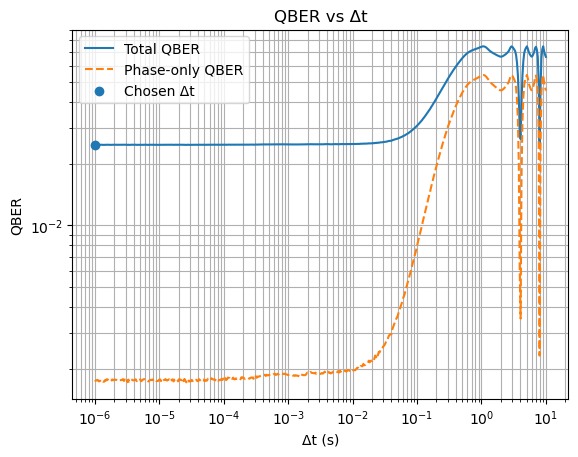

In [128]:
res = choose_delta_t_and_qber(
    ON_OFF_x, ON_OFF_y,
    psd_in_dbc=False,   # set True if your PSD column is in dBc/Hz
    V0=0.96,            # sensible baseline visibility for a well-aligned hybrid AMZI
    M=16,               # or None if you don’t phase-slice
    target_total_qber=0.02,
    dt_lo=dt_lo, dt_hi=dt_hi,
    n_dt=500
)

print(f"Chosen Δt  : {res['delta_t_s']:.3e} s")
print(f"Total QBER : {100*res['qber_total']:.2f}%  (phase-only {100*res['qber_phase_only']:.2f}%)")
print(f"σφ         : {res['sigma_phi_rad']:.3f} rad")
print(f"C_slice    : {res['C_slice']:.6f}")

# Plot QBER vs Δt (marks the chosen Δt)
plot_qber_vs_dt(res, show_phase_only=True)

Chosen Δt  : 1.000e-06 s
Total QBER : 2.47%  (phase-only 0.17%)
σφ         : 0.082 rad
C_slice    : 0.993587


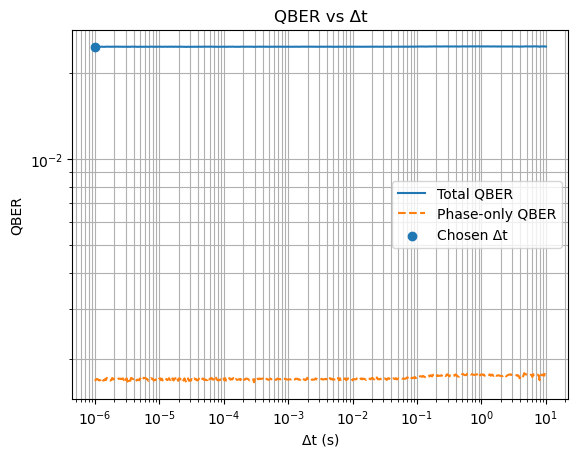

In [129]:
res2 = choose_delta_t_and_qber(
    ON_ON_x, ON_ON_y,
    psd_in_dbc=False,   # set True if your PSD column is in dBc/Hz
    V0=0.96,            # sensible baseline visibility for a well-aligned hybrid AMZI
    M=16,               # or None if you don’t phase-slice
    target_total_qber=0.02,
    dt_lo=dt_lo, dt_hi=dt_hi,
    n_dt=500
)
print(f"Chosen Δt  : {res2['delta_t_s']:.3e} s")
print(f"Total QBER : {100*res2['qber_total']:.2f}%  (phase-only {100*res2['qber_phase_only']:.2f}%)")
print(f"σφ         : {res2['sigma_phi_rad']:.3f} rad")
print(f"C_slice    : {res2['C_slice']:.6f}")

# Plot QBER vs Δt (marks the chosen Δt)
plot_qber_vs_dt(res2, show_phase_only=True)

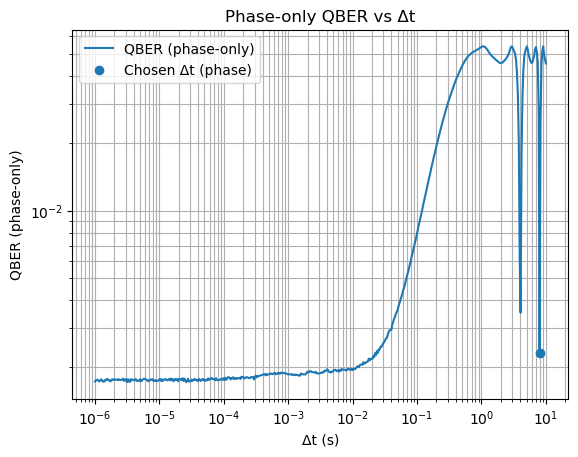

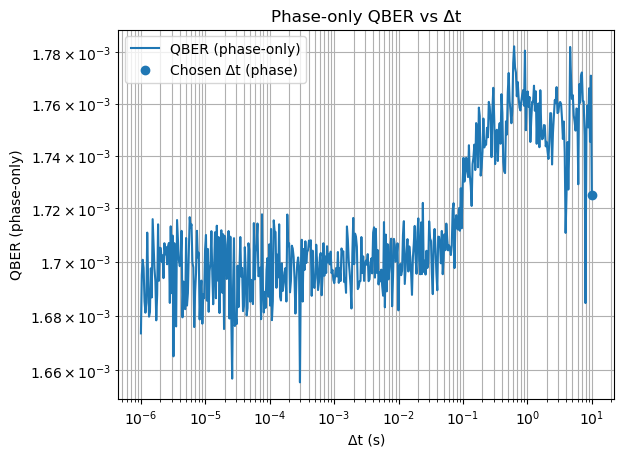

In [132]:
plot_phase_qber_vs_dt(res, mark="phase")
plot_phase_qber_vs_dt(res2, mark="phase")


In [72]:
Z4_y, Z4_x = np.load('Z4_y.npy'), np.load('Z4_x.npy')
Z5_y, Z5_x = np.load('Z5_y.npy'), np.load('Z5_x.npy')
Z6_y, Z6_x = np.load('Z6_y.npy'), np.load('Z6_x.npy')

Chosen Δt  : 1.000e-06 s
Total QBER : 2.33%  (phase-only 0.02%)
σφ         : 0.030 rad
C_slice    : 0.993587


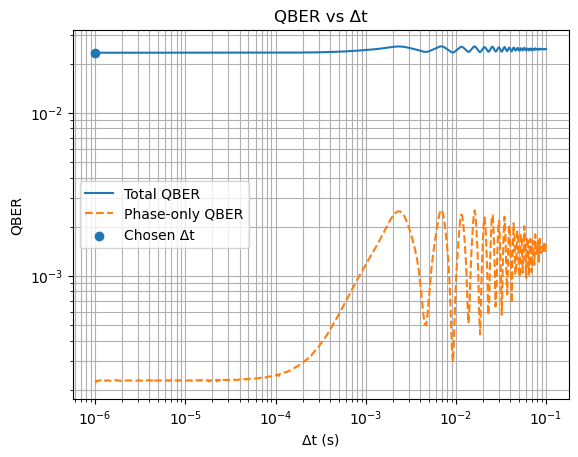

In [92]:
res1 = choose_delta_t_and_qber(
    Z4_x, Z4_y,
    psd_in_dbc=False,   # set True if your PSD column is in dBc/Hz
    V0=0.96,            # sensible baseline visibility for a well-aligned hybrid AMZI
    M=16,               # or None if you don’t phase-slice
    target_total_qber=0.02,
    dt_lo=dt_lo, dt_hi=dt_hi,
    n_dt=500
)
print(f"Chosen Δt  : {res1['delta_t_s']:.3e} s")
print(f"Total QBER : {100*res1['qber_total']:.2f}%  (phase-only {100*res1['qber_phase_only']:.2f}%)")
print(f"σφ         : {res1['sigma_phi_rad']:.3f} rad")
print(f"C_slice    : {res1['C_slice']:.6f}")

# Plot QBER vs Δt (marks the chosen Δt)
plot_qber_vs_dt(res1, show_phase_only=True)

Chosen Δt  : 1.000e-06 s
Total QBER : 2.33%  (phase-only 0.02%)
σφ         : 0.030 rad
C_slice    : 0.993587


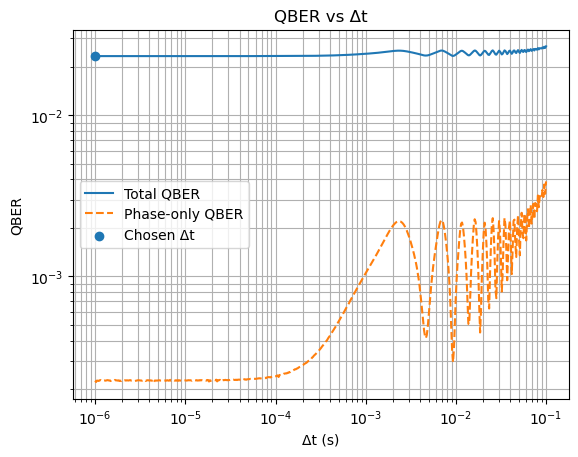

In [93]:
res2 = choose_delta_t_and_qber(
    Z5_x, Z5_y,
    psd_in_dbc=False,   # set True if your PSD column is in dBc/Hz
    V0=0.96,            # sensible baseline visibility for a well-aligned hybrid AMZI
    M=16,               # or None if you don’t phase-slice
    target_total_qber=0.02,
    dt_lo=dt_lo, dt_hi=dt_hi,
    n_dt=500
)
print(f"Chosen Δt  : {res2['delta_t_s']:.3e} s")
print(f"Total QBER : {100*res2['qber_total']:.2f}%  (phase-only {100*res2['qber_phase_only']:.2f}%)")
print(f"σφ         : {res2['sigma_phi_rad']:.3f} rad")
print(f"C_slice    : {res2['C_slice']:.6f}")

# Plot QBER vs Δt (marks the chosen Δt)
plot_qber_vs_dt(res2, show_phase_only=True)

Chosen Δt  : 1.000e-06 s
Total QBER : 2.33%  (phase-only 0.02%)
σφ         : 0.031 rad
C_slice    : 0.993587


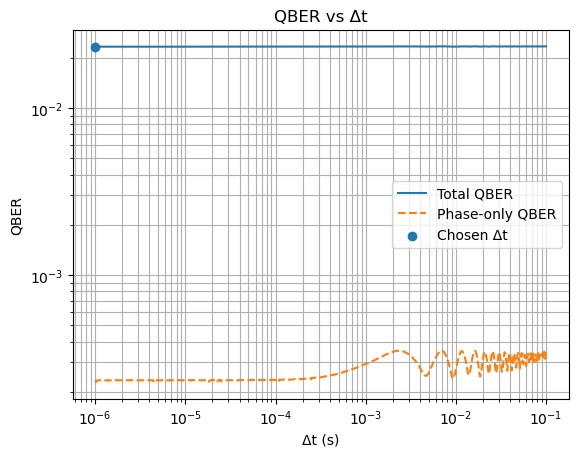

In [94]:
res3 = choose_delta_t_and_qber(
    Z6_x, Z6_y,
    psd_in_dbc=False,   # set True if your PSD column is in dBc/Hz
    V0=0.96,            # sensible baseline visibility for a well-aligned hybrid AMZI
    M=16,               # or None if you don’t phase-slice
    target_total_qber=0.02,
    dt_lo=dt_lo, dt_hi=dt_hi,
    n_dt=500
)
print(f"Chosen Δt  : {res3['delta_t_s']:.3e} s")
print(f"Total QBER : {100*res3['qber_total']:.2f}%  (phase-only {100*res3['qber_phase_only']:.2f}%)")
print(f"σφ         : {res3['sigma_phi_rad']:.3f} rad")
print(f"C_slice    : {res3['C_slice']:.6f}")

# Plot QBER vs Δt (marks the chosen Δt)
plot_qber_vs_dt(res3, show_phase_only=True)

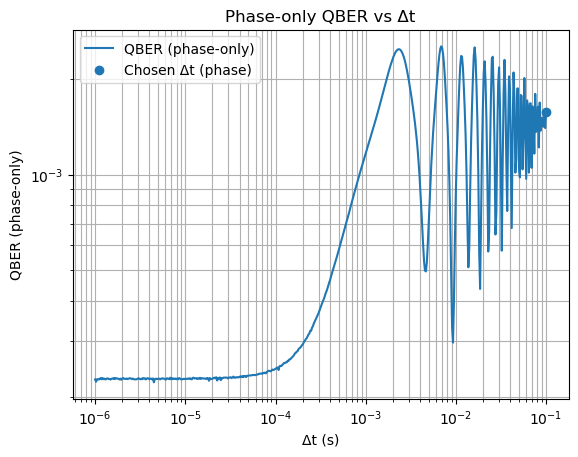

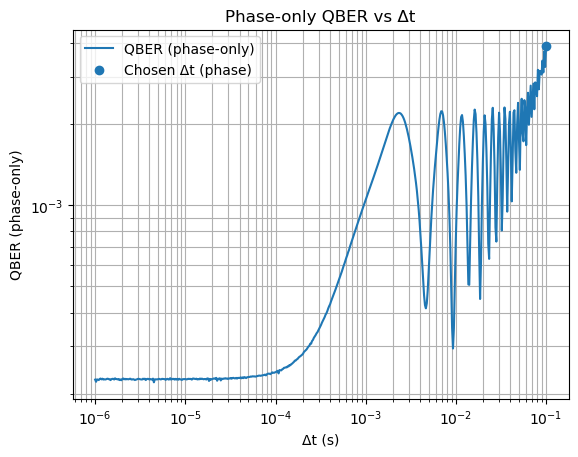

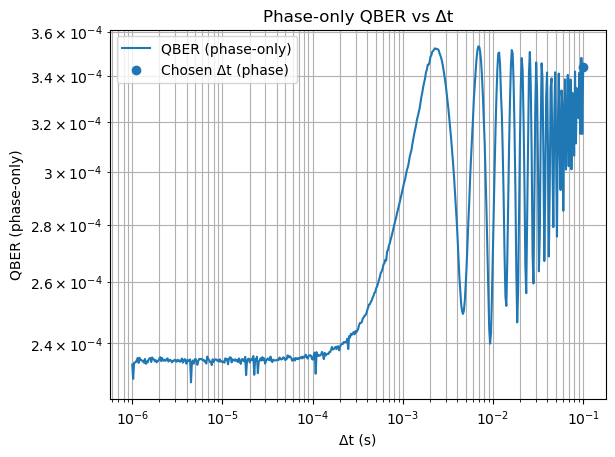

In [98]:
plot_phase_qber_vs_dt(res1, mark="phase")
plot_phase_qber_vs_dt(res2, mark="phase")
plot_phase_qber_vs_dt(res3, mark="phase")

In [110]:
import numpy as np

def _to_linear_psd(psd, in_dbc=False):
    """Return single-sided phase PSD in linear units [rad^2/Hz]."""
    psd = np.asarray(psd, dtype=float)
    if in_dbc:
        return 2.0 * 10.0**(psd / 10.0)  # L(f) dBc/Hz -> S_phi [rad^2/Hz]
    return psd

def _common_log_grid(f_off, f_on, N=2000):
    """Make a common log-frequency grid spanning the overlap of OFF/ON arrays."""
    fmin = max(np.min(f_off[f_off > 0]), np.min(f_on[f_on > 0]))
    fmax = min(np.max(f_off), np.max(f_on))
    if not np.isfinite(fmin) or not np.isfinite(fmax) or fmax <= fmin:
        raise ValueError("Frequency arrays must overlap and be > 0.")
    return np.logspace(np.log10(fmin), np.log10(fmax), N)

def _interp_log(f_src, y_src, f_dst):
    """Log-log interpolation (robust for PSDs)."""
    return 10.0**np.interp(np.log10(f_dst), np.log10(f_src), np.log10(np.maximum(y_src, 1e-300)))

def _smooth_running_median(x, y, nbins=64):
    """Median smooth on log-x bins; returns (x_mid, y_med) then interp back to x."""
    lx = np.log10(x)
    edges = np.linspace(lx.min(), lx.max(), nbins+1)
    xm, ym = [], []
    for i in range(nbins):
        m = (lx >= edges[i]) & (lx < edges[i+1])
        if np.any(m):
            xm.append(10**(0.5*(edges[i]+edges[i+1])))
            ym.append(np.median(y[m]))
    if len(xm) < 4:
        return y  # not enough points to smooth
    xm, ym = np.array(xm), np.array(ym)
    return 10.0**np.interp(np.log10(x), np.log10(xm), np.log10(np.maximum(ym, 1e-300)))

def estimate_bandwidth_and_deltat(
    f_hz_off, psd_off, f_hz_on, psd_on,
    *, psd_in_dbc=False, median_bins=64, alpha_range=(0.1, 0.3), alpha_default=0.2
):
    """
    Inputs:
      f_hz_off, psd_off : OFF (open-loop) frequencies & PSD
      f_hz_on,  psd_on  : ON  (closed-loop) frequencies & PSD
      psd_in_dbc        : set True if PSDs are L(f) in dBc/Hz (otherwise rad^2/Hz)
      median_bins       : log-frequency bins for median smoothing of the ratio
      alpha_range       : Δt ≈ α/f_BW range reported
      alpha_default     : nominal α used for the main Δt

    Returns dict with f_BW (Hz), Δt_default (s), Δt_range (s), arrays for plotting.
    """
    # Convert to linear units if needed
    S_off = _to_linear_psd(psd_off, in_dbc=psd_in_dbc)
    S_on  = _to_linear_psd(psd_on,  in_dbc=psd_in_dbc)

    # Common grid & interpolation
    fgrid = _common_log_grid(np.asarray(f_hz_off), np.asarray(f_hz_on))
    Soff_g = _interp_log(f_hz_off, S_off, fgrid)
    Son_g  = _interp_log(f_hz_on,  S_on,  fgrid)

    # Suppression ratio (ON/OFF) and smoothing
    R = np.clip(Son_g / np.maximum(Soff_g, 1e-300), 1e-6, 1e6)
    R_smooth = _smooth_running_median(fgrid, R, nbins=median_bins)
    Rdb = 10*np.log10(R_smooth)

    # Find bandwidth at -6 dB crossing (i.e., |S|^2 = 0.25 -> |L|≈1)
    target_db = -6.0
    # Ensure monotonic-ish by taking the first crossing from low f upward
    # (low f should be most suppressed -> most negative dB)
    idx = np.where((Rdb[:-1] <= target_db) & (Rdb[1:] > target_db))[0]
    if idx.size == 0:
        # Fallback: pick freq where Rdb is closest to -6 dB
        i = int(np.argmin(np.abs(Rdb - target_db)))
        f_bw = float(fgrid[i])
        crossed = False
    else:
        i = idx[0]
        # Linear interpolate in dB between points i and i+1
        x0, x1 = Rdb[i], Rdb[i+1]
        f0, f1 = fgrid[i], fgrid[i+1]
        w = (target_db - x0) / (x1 - x0) if x1 != x0 else 0.0
        f_bw = float(f0 * (f1/f0)**w)  # interpolate in log-frequency
        crossed = True

    # Δt estimates
    a_lo, a_hi = alpha_range
    dt_default = alpha_default / f_bw
    dt_range = (a_lo / f_bw, a_hi / f_bw)

    return {
        "f_bw_hz": f_bw,
        "crossed_at_-6dB": bool(crossed),
        "delta_t_s": dt_default,
        "delta_t_range_s": dt_range,
        "ratio_db": Rdb,
        "freq_hz": fgrid,
    }

# -------- Optional plotting --------
def plot_suppression(result, *, title="AOM servo suppression (ON/OFF)"):
    """
    Plot the smoothed suppression ratio (dB) and mark the -6 dB bandwidth.
    """
    import matplotlib.pyplot as plt
    f = result["freq_hz"]; Rdb = result["ratio_db"]; fbw = result["f_bw_hz"]
    plt.figure()
    plt.semilogx(f, Rdb, label="ON/OFF (smoothed)")
    plt.axhline(-6, linestyle="--", linewidth=1, label="-6 dB")
    plt.axvline(fbw, linestyle="--", linewidth=1, label=f"f_BW ≈ {fbw:.2g} Hz")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Suppression (dB)")
    plt.title(title)
    plt.grid(True, which="both")
    plt.legend()
    plt.show()


Loop bandwidth f_BW ≈ 3.16e+04 Hz (-6 dB crossing)
Δt ≈ 0.01 ms  (range: 0.00–0.01 ms)


C:\Users\Ry\AppData\Local\Temp\ipykernel_28548\1884925909.py:20: RuntimeWarning: divide by zero encountered in log10
  return 10.0**np.interp(np.log10(f_dst), np.log10(f_src), np.log10(np.maximum(y_src, 1e-300)))


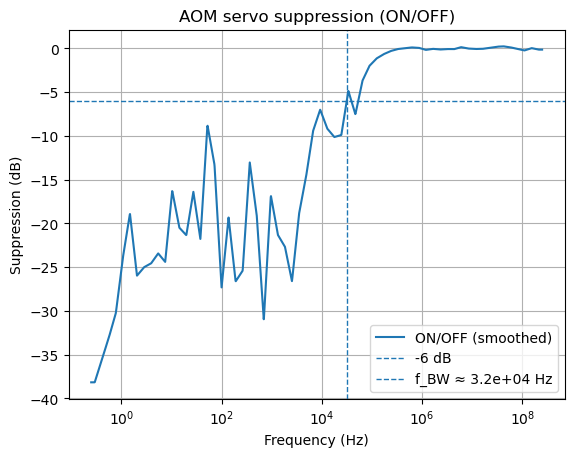

In [116]:
# Your arrays:
# f_off, Sphi_off = ...  # OFF PSD
# f_on,  Sphi_on  = ...  # ON  PSD
# If they are in dBc/Hz instead of rad^2/Hz, set psd_in_dbc=True.

res = estimate_bandwidth_and_deltat(off_f, off_Pxx, on_f, on_Pxx,
                                    psd_in_dbc=False,  # True if in dBc/Hz
                                    median_bins=64, alpha_range=(0.1, 0.3), alpha_default=0.2)

status = "-6 dB crossing" if res["crossed_at_-6dB"] else "closest point"
print(f"Loop bandwidth f_BW ≈ {res['f_bw_hz']:.3g} Hz ({status})")
print(f"Δt ≈ {res['delta_t_s']*1e3:.2f} ms  (range: {res['delta_t_range_s'][0]*1e3:.2f}–{res['delta_t_range_s'][1]*1e3:.2f} ms)")

# Optional plot
plot_suppression(res)
